<a href="https://colab.research.google.com/github/erre-x-erre/Metodos_Numericos_I/blob/main/M%C3%A9todo%20de%20Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#***<font color="green">"MÉTODO DE NEVILLE".</font>***

El objetivo es aproximar el valor de una función mediante
el método de interpolación de Neville.

Para este ejercicio utilizaremos la función:
$f(x)=\frac{1}{1+25x^2}$

Utilizaremos NumPy para los cálculos numéricos, Matplotlib para las gráficas y Pandas para construir la tabla de iteraciones.

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import display, Markdown, Math, HTML

In [62]:
# Definimos la función
def f(x):
    return 1/(1+25*x**2)

In [63]:
# Número de nodos
n = 15

# Intervalo de interpolación
a = -1
b = 1

# Generamos los nodos equidistantes
x = np.linspace(a, b, n+1)

# Evaluamos la función en los nodos
y = f(x)

# Mostramos los datos
datos = pd.DataFrame({'x_i': x,'f(x_i)': y})

display(datos)

,x_i,f(x_i)
0,-1.000000,0.038462
1,-0.866667,0.050562
2,-0.733333,0.069231
3,-0.600000,0.100000
4,-0.466667,0.155172
5,-0.333333,0.264706
6,-0.200000,0.500000
7,-0.066667,0.900000
8,0.066667,0.900000
9,0.200000,0.500000


In [64]:
# Definimos el método de Neville
def neville(x, y, valor):
    n = len(x) - 1

    # Creamos una matriz de ceros
    Q = np.zeros((n+1, n+1))

    # Primera columna: valores de la función
    Q[:, 0] = y

    # Construcción de la tabla de Neville
    for i in range(1, n+1):

        for j in range(1, i+1):

            Q[i, j] = ((valor - x[i-j]) * Q[i, j-1] - (valor - x[i]) * Q[i-1, j-1]) / (x[i] - x[i-j])

    # Resultado final
    resultado = Q[n, n]
    return Q, resultado

In [65]:
# Punto donde queremos interpolar
valor = 0.5

# Aplicamos el método de Neville
Q, resultado = neville(x, y, valor)

# Evaluación exacta de la función
exacto = f(valor)

# Calculamos el error absoluto
error = abs(exacto - resultado)

In [66]:
# Creamos los nombres de las columnas
columnas = [f'Q{i},j' for i in range(n+1)]

# Construimos la tabla
tabla = pd.DataFrame(Q, columns=columnas)

# Ocultamos los ceros que corresponden a posiciones no utilizadas
tabla = tabla.replace(0, np.nan)

# Mostramos la tabla
display(HTML("""<h3 style="color:green;">Tabla de iteraciones de Neville</h3>"""))

display(tabla.style.format("{:.8f}", na_rep="-"))

print("Resultados Obtenidos:")
print(f"Punto de interpolación: {valor}")
print(f"Valor exacto:           {exacto:.10f}")
print(f"Valor aproximado:       {resultado:.10f}")
print(f"Error absoluto:         {error:.10f}")

print("Solución Final: P({0:.1f}) = {1:.10f}".format(valor, resultado))

,"Q0,j","Q1,j","Q2,j","Q3,j","Q4,j","Q5,j","Q6,j","Q7,j","Q8,j","Q9,j","Q10,j","Q11,j","Q12,j","Q13,j","Q14,j","Q15,j"
0,0.03846154,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
1,0.05056180,0.17458946,-,-,-,-,-,-,-,-,-,-,-,-,-,-
2,0.06923077,0.24191876,0.55331677,-,-,-,-,-,-,-,-,-,-,-,-,-
3,0.10000000,0.35384615,0.81554667,1.53667891,-,-,-,-,-,-,-,-,-,-,-,-
4,0.15517241,0.55517241,1.28498011,2.41944424,4.01945639,-,-,-,-,-,-,-,-,-,-,-
5,0.26470588,0.94929006,2.18090771,4.04742355,6.59114121,9.80574724,-,-,-,-,-,-,-,-,-,-
6,0.50000000,1.73529412,3.79855477,6.62943712,10.01832994,13.61687810,16.95161760,-,-,-,-,-,-,-,-,-
7,0.90000000,2.60000000,4.43750000,5.34267241,3.97548491,-1.16093336,-11.62854980,-28.98079429,-,-,-,-,-,-,-,-
8,0.90000000,0.90000000,-1.86250000,-8.68750000,-20.08701509,-35.72764009,-54.45127290,-74.33325148,-92.75768721,-,-,-,-,-,-,-
9,0.50000000,-0.40000000,-1.86250000,-1.86250000,1.97656250,11.90517241,29.76747710,56.83778960,93.72964491,140.35147794,-,-,-,-,-,-


Resultados Obtenidos:
Punto de interpolación: 0.5
Valor exacto:           0.1379310345
Valor aproximado:       0.1235510543
Error absoluto:         0.0143799802
Solución Final: P(0.5) = 0.1235510543


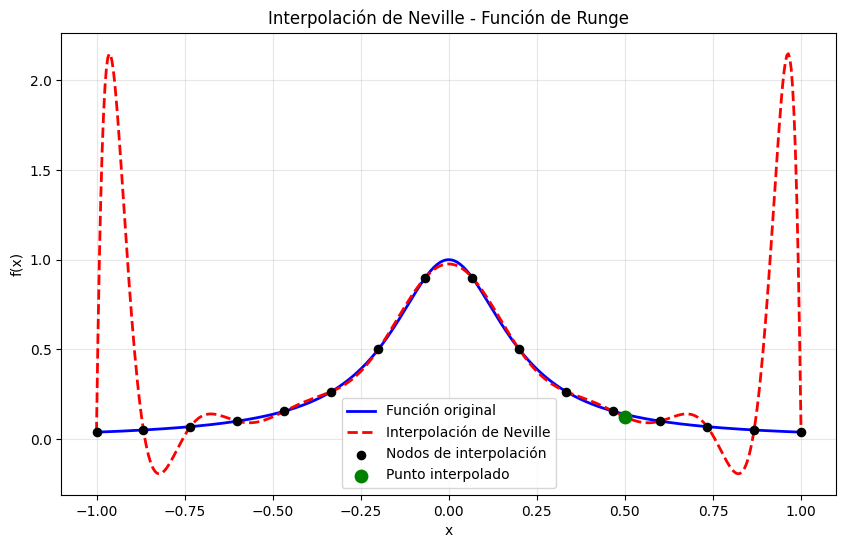

In [67]:
# Generamos valores para la gráfica
xgraf = np.linspace(a, b, 500)

# Evaluamos la función original
ygraf = f(xgraf)

# Evaluamos el polinomio mediante Neville
Pgraf = np.array([neville(x, y, valor_x)[1]for valor_x in xgraf])

# Construimos la gráfica
plt.figure(figsize=(10,6))

# Función original
plt.plot(xgraf, ygraf, color='blue', linewidth=2, label='Función original')

# Polinomio interpolador
plt.plot(xgraf, Pgraf, color='red', linestyle='--', linewidth=2, label='Interpolación de Neville')

# Nodos de interpolación
plt.scatter(x, y, color='black', s=35, label='Nodos de interpolación', zorder=3)

# Punto evaluado
plt.scatter(valor, resultado, color='green', s=80, label='Punto interpolado', zorder=4)

plt.title('Interpolación de Neville - Función de Runge')
plt.xlabel('x')
plt.ylabel('f(x)')

plt.legend()
plt.grid(alpha=0.3)

plt.show()